# 03 — CNN vs ResNet vs ConvLSTM Comparison (Channel 1)

This notebook compares the three CycloneConnect models on **the same test observations**:

- **CNN:** one 64 × 64 Channel 1 image
- **ResNet-style model:** one 64 × 64 Channel 1 image with residual connections
- **ConvLSTM:** four 64 × 64 Channel 1 images, spaced three hours apart

All models predict `TARGET_WIND`, the six-hour-ahead wind speed in knots.



## 1. Mount Google Drive and load saved results

In [3]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error

RESULTS_DIR = Path('/content/drive/MyDrive/cyclone/model_results')

files = {
    'CNN': {
        'metrics': RESULTS_DIR / 'cnn_channel1_metrics.json',
        'predictions': RESULTS_DIR / 'cnn_channel1_test_predictions.csv'
    },
    'ResNet': {
        'metrics': RESULTS_DIR / 'resnet_channel1_metrics.json',
        'predictions': RESULTS_DIR / 'resnet_channel1_test_predictions.csv'
    },
    'ConvLSTM': {
        'metrics': RESULTS_DIR / 'convlstm_channel1_metrics.json',
        'predictions': RESULTS_DIR / 'convlstm_channel1_test_predictions.csv'
    }
}

missing = [
    str(path)
    for model_files in files.values()
    for path in model_files.values()
    if not path.exists()
]

for model_name, model_files in files.items():
    for kind, path in model_files.items():
        print(('FOUND  ' if path.exists() else 'MISSING'), model_name, kind, path)

if missing:
    raise FileNotFoundError(
        "Some result files are missing. Run all three model notebooks through "
        "their save-results section first. Missing files:\n- " + "\n- ".join(missing)
    )

metrics = {}
predictions = {}

for model_name, model_files in files.items():
    with open(model_files['metrics'], 'r', encoding='utf-8') as f:
        metrics[model_name] = json.load(f)
    predictions[model_name] = pd.read_csv(model_files['predictions'])

print("\nSaved headline metrics:")
display(pd.DataFrame(metrics).T)

for model_name, df in predictions.items():
    print(f"\n{model_name} prediction columns:", df.columns.tolist())
    print(f"{model_name} prediction rows:", len(df))
    display(df.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FOUND   CNN metrics /content/drive/MyDrive/cyclone/model_results/cnn_channel1_metrics.json
FOUND   CNN predictions /content/drive/MyDrive/cyclone/model_results/cnn_channel1_test_predictions.csv
FOUND   ResNet metrics /content/drive/MyDrive/cyclone/model_results/resnet_channel1_metrics.json
FOUND   ResNet predictions /content/drive/MyDrive/cyclone/model_results/resnet_channel1_test_predictions.csv
FOUND   ConvLSTM metrics /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_metrics.json
FOUND   ConvLSTM predictions /content/drive/MyDrive/cyclone/model_results/convlstm_channel1_test_predictions.csv

Saved headline metrics:


,model,channel,input,target,test_samples,test_mae_knots,test_rmse_knots,normalization_train_pixel_mean,normalization_train_pixel_std,seed,epochs_trained
CNN,CNN,1,single 64x64 satellite image,"TARGET_WIND (six-hour-ahead wind speed, knots)",1013,13.650764,18.341037,239.261448,31.936358,NaN,NaN
ResNet,ResNet-style CNN,1,single 64x64 grayscale satellite image,"TARGET_WIND (six-hour-ahead wind speed, knots)",1013,11.392761,15.006128,239.261448,31.936358,42,35
ConvLSTM,ConvLSTM,1,"four 64x64 satellite images, 3 hours apart","TARGET_WIND (six-hour-ahead wind speed, knots)",1013,12.525309,17.015584,238.528954,31.757712,NaN,NaN



CNN prediction columns: ['SID', 'T', 'actual_wind_knots', 'predicted_wind_knots']
CNN prediction rows: 1013


,SID,T,actual_wind_knots,predicted_wind_knots
0,2024145N14087,2024-05-24 18:00:00,30.0,17.818493
1,2024145N14087,2024-05-24 21:00:00,30.0,13.889433
2,2024145N14087,2024-05-25 09:00:00,35.0,42.819580



ResNet prediction columns: ['SID', 'timestamp', 'actual_wind_knots', 'predicted_wind_knots']
ResNet prediction rows: 1013


,SID,timestamp,actual_wind_knots,predicted_wind_knots
0,2024141N03142,2024-05-25 06:00:00,35.0,43.054256
1,2024141N03142,2024-05-25 12:00:00,45.0,28.202356
2,2024141N03142,2024-05-25 18:00:00,50.0,47.422703



ConvLSTM prediction columns: ['SID', 'END_TIME', 'actual_wind_knots', 'predicted_wind_knots']
ConvLSTM prediction rows: 1013


,SID,END_TIME,actual_wind_knots,predicted_wind_knots
0,2024141N03142,2024-05-25 06:00:00,35.0,53.135834
1,2024141N03142,2024-05-25 12:00:00,45.0,59.963710
2,2024141N03142,2024-05-25 18:00:00,50.0,43.782604


## 2. Normalize columns and identify matching keys

In [4]:
def normalize_colname(name):
    return ''.join(ch.lower() for ch in str(name) if ch.isalnum())

def find_column(df, aliases):
    lookup = {normalize_colname(c): c for c in df.columns}
    for alias in aliases:
        key = normalize_colname(alias)
        if key in lookup:
            return lookup[key]
    return None

sid_aliases = ['SID', 'storm_id', 'cyclone_id', 'stormid']
time_aliases = ['T', 'END_TIME', 'ISO_TIME', 'timestamp', 'datetime', 'time', 'valid_time', 'target_time']
actual_aliases = ['actual_wind_knots', 'actual_wind', 'TARGET_WIND', 'target_wind', 'actual']
prediction_aliases = ['predicted_wind_knots', 'prediction', 'predicted_wind', 'y_pred', 'pred']

normalized = {}

for model_name, df_original in predictions.items():
    df = df_original.copy()

    sid_col = find_column(df, sid_aliases)
    time_col = find_column(df, time_aliases)
    actual_col = find_column(df, actual_aliases)
    pred_col = find_column(df, prediction_aliases)

    if not all([sid_col, time_col, actual_col, pred_col]):
        raise ValueError(
            f"{model_name} CSV needs cyclone ID, timestamp, actual wind, and prediction columns. "
            f"Detected: SID={sid_col}, time={time_col}, actual={actual_col}, prediction={pred_col}. "
            f"Available columns: {df.columns.tolist()}"
        )

    df['_sid_key'] = df[sid_col].astype('string').str.strip()
    df['_time_key'] = pd.to_datetime(df[time_col], errors='coerce', utc=True)
    df[f'actual_{model_name}'] = pd.to_numeric(df[actual_col], errors='coerce')
    df[f'prediction_{model_name}'] = pd.to_numeric(df[pred_col], errors='coerce')

    df = df.dropna(subset=['_sid_key', '_time_key', f'actual_{model_name}', f'prediction_{model_name}']).copy()

    duplicate_count = int(df.duplicated(['_sid_key', '_time_key']).sum())
    print(f"{model_name}: usable rows={len(df)}, duplicate cyclone/timestamp keys={duplicate_count}")

    if duplicate_count:
        raise ValueError(
            f"{model_name} has duplicate (cyclone ID, timestamp) keys. "
            "Resolve duplicates before comparing models."
        )

    normalized[model_name] = df[[
        '_sid_key', '_time_key',
        f'actual_{model_name}', f'prediction_{model_name}'
    ]]

print("\nMatching rule: cyclone ID + timestamp. Timestamps are parsed as UTC for consistent formatting.")

CNN: usable rows=1013, duplicate cyclone/timestamp keys=0
ResNet: usable rows=1013, duplicate cyclone/timestamp keys=0
ConvLSTM: usable rows=1013, duplicate cyclone/timestamp keys=0

Matching rule: cyclone ID + timestamp. Timestamps are parsed as UTC for consistent formatting.


## 3. Match all three models on common observations

In [5]:
cnn = normalized['CNN']
resnet = normalized['ResNet']
convlstm = normalized['ConvLSTM']

matched = cnn.merge(
    resnet,
    on=['_sid_key', '_time_key'],
    how='inner',
    validate='one_to_one'
)
matched = matched.merge(
    convlstm,
    on=['_sid_key', '_time_key'],
    how='inner',
    validate='one_to_one'
)

print("CNN usable test rows:", len(cnn))
print("ResNet usable test rows:", len(resnet))
print("ConvLSTM usable test rows:", len(convlstm))
print("Observations shared by all three models:", len(matched))

if matched.empty:
    raise ValueError(
        "No common observations were found. Check whether all prediction files use "
        "the same cyclone ID and timestamp convention."
    )

actual_cols = ['actual_CNN', 'actual_ResNet', 'actual_ConvLSTM']
actual_values = matched[actual_cols].to_numpy(dtype=float)
max_actual_difference = float(np.max(np.abs(actual_values - actual_values[:, [0]])))

print("Maximum difference among actual target values (knots):", max_actual_difference)

TOLERANCE = 1e-4
if max_actual_difference > TOLERANCE:
    mismatches = matched.loc[
        (matched['actual_CNN'] - matched['actual_ResNet']).abs().gt(TOLERANCE)
        | (matched['actual_CNN'] - matched['actual_ConvLSTM']).abs().gt(TOLERANCE)
    ]
    display(mismatches.head(10))
    raise ValueError(
        "Actual target values disagree for some matched keys. Do not average the targets "
        "or compare the models until the timestamp/target alignment is checked."
    )

# Use one actual-target column after verifying all three agree.
matched['actual_wind'] = matched['actual_CNN']

matched = matched[[
    '_sid_key', '_time_key', 'actual_wind',
    'prediction_CNN', 'prediction_ResNet', 'prediction_ConvLSTM'
]].rename(columns={'_sid_key': 'SID', '_time_key': 'timestamp'})

display(matched.head())

CNN usable test rows: 1013
ResNet usable test rows: 1013
ConvLSTM usable test rows: 1013
Observations shared by all three models: 1013
Maximum difference among actual target values (knots): 0.0


,SID,timestamp,actual_wind,prediction_CNN,prediction_ResNet,prediction_ConvLSTM
0,2024145N14087,2024-05-24 18:00:00+00:00,30.0,17.818493,19.323847,35.587450
1,2024145N14087,2024-05-24 21:00:00+00:00,30.0,13.889433,22.189620,26.279190
2,2024145N14087,2024-05-25 09:00:00+00:00,35.0,42.819580,28.305490,31.340900
3,2024141N03142,2024-05-25 12:00:00+00:00,45.0,41.872310,28.202356,59.963710
4,2024145N14087,2024-05-25 12:00:00+00:00,40.0,28.834938,27.883436,27.389986


## 4. Calculate MAE and RMSE on the same observations

In [6]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = predicted - actual
    return {
        'MAE (knots)': float(np.mean(np.abs(errors))),
        'RMSE (knots)': float(np.sqrt(np.mean(errors ** 2)))
    }

model_specs = [
    ('CNN', 'One Channel 1 image'),
    ('ResNet', 'One Channel 1 image + residual connections'),
    ('ConvLSTM', 'Four Channel 1 images, 3 hours apart')
]

rows = []
for model_name, input_description in model_specs:
    result = regression_metrics(matched['actual_wind'], matched[f'prediction_{model_name}'])
    rows.append({
        'Model': model_name,
        'Input': input_description,
        'Common test samples': len(matched),
        **result
    })

comparison = pd.DataFrame(rows).sort_values('MAE (knots)').reset_index(drop=True)
display(comparison.round(4))

best_mae = comparison.loc[comparison['MAE (knots)'].idxmin(), 'Model']
best_rmse = comparison.loc[comparison['RMSE (knots)'].idxmin(), 'Model']

print(f"Lowest MAE on common test observations: {best_mae}")
print(f"Lowest RMSE on common test observations: {best_rmse}")
print("Lower MAE and RMSE indicate smaller prediction errors.")

,Model,Input,Common test samples,MAE (knots),RMSE (knots)
0,ResNet,One Channel 1 image + residual connections,1013,11.3928,15.0061
1,ConvLSTM,"Four Channel 1 images, 3 hours apart",1013,12.5253,17.0156
2,CNN,One Channel 1 image,1013,13.6508,18.3410


Lowest MAE on common test observations: ResNet
Lowest RMSE on common test observations: ResNet
Lower MAE and RMSE indicate smaller prediction errors.


## 5. Plot model comparison

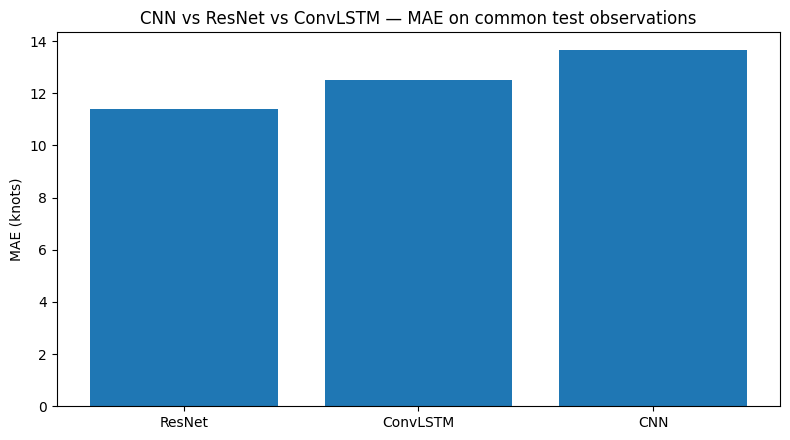

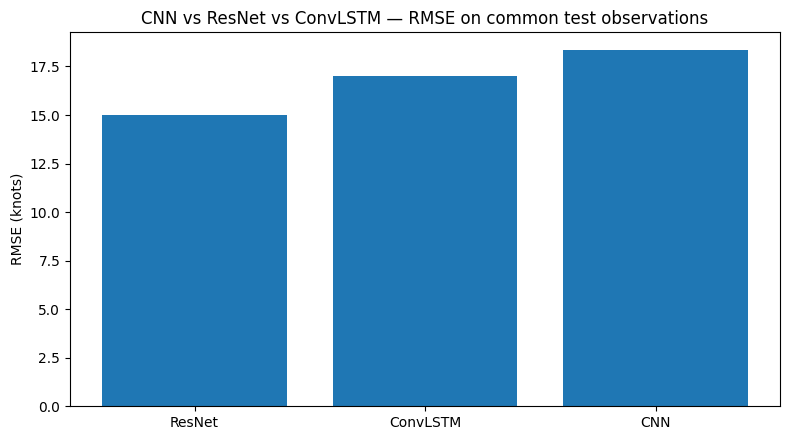

In [7]:
plt.figure(figsize=(8, 4.5))
plt.bar(comparison['Model'], comparison['MAE (knots)'])
plt.ylabel('MAE (knots)')
plt.title('CNN vs ResNet vs ConvLSTM — MAE on common test observations')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(comparison['Model'], comparison['RMSE (knots)'])
plt.ylabel('RMSE (knots)')
plt.title('CNN vs ResNet vs ConvLSTM — RMSE on common test observations')
plt.tight_layout()
plt.show()

## 6. Compare absolute prediction errors

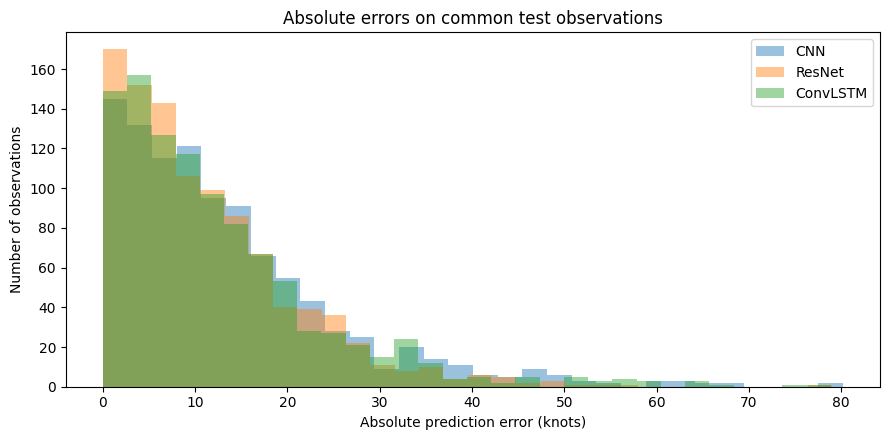

In [8]:
for model_name in ['CNN', 'ResNet', 'ConvLSTM']:
    matched[f'{model_name}_absolute_error'] = (
        matched[f'prediction_{model_name}'] - matched['actual_wind']
    ).abs()

plt.figure(figsize=(9, 4.5))
for model_name in ['CNN', 'ResNet', 'ConvLSTM']:
    plt.hist(
        matched[f'{model_name}_absolute_error'],
        bins=30,
        alpha=0.45,
        label=model_name
    )
plt.xlabel('Absolute prediction error (knots)')
plt.ylabel('Number of observations')
plt.title('Absolute errors on common test observations')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Save the three-model comparison to Google Drive

In [9]:
comparison_path = RESULTS_DIR / 'channel1_model_comparison_3models_common_samples.csv'
matched_path = RESULTS_DIR / 'channel1_3models_matched_test_predictions.csv'

comparison.to_csv(comparison_path, index=False)
matched.to_csv(matched_path, index=False)

print("Saved comparison table:", comparison_path)
print("Saved matched predictions:", matched_path)

Saved comparison table: /content/drive/MyDrive/cyclone/model_results/channel1_model_comparison_3models_common_samples.csv
Saved matched predictions: /content/drive/MyDrive/cyclone/model_results/channel1_3models_matched_test_predictions.csv


## Before interpreting the results

1. Run the CNN, ResNet, and ConvLSTM notebooks through the cells that save their metrics and test-prediction CSV files.
2. Confirm all three files appear in `MyDrive/cyclone/model_results/`.
3. Run this comparison notebook from top to bottom.
4. Report the **common-sample MAE and RMSE** from this notebook as the fair three-model comparison. The standalone metrics in each model notebook may be based on different test rows.
5. If the notebook stops because target values disagree or no common rows are found, investigate timestamp and target alignment; do not average the target values to force a match.